#   1 Problem Statement

The objective of this project is to identify which States and
Union Territories in India should be prioritised for plastic-waste
management action.

The analysis uses CPCB plastic-waste generation data from
2016-17 to 2020-21.

The project aims to compare plastic-waste generation across
States/UTs, identify major trends and provide data-driven
recommendations to support government decision-making.

#  2. Exploratory Data Analysis (EDA)



## 2.1 Loading a Dataset

The dataset contains State/UT-wise plastic-waste generation
figures for five financial years, from 2016-17 to 2020-21.

In [0]:
import pandas as pd

In [0]:
df = pd.read_csv("/Volumes/project/default/project/RS_Session_266_AU_1159_B_and_C_1.csv")

In [0]:
display(df)

Sl. No.,State/UT-wise,2016-17,2017-18,2018-19,2019-20,2020-21
1,Andhra Pradesh,82863.0,null,66314.0,46222.0,39626.45
2,Arunachal Pradesh,null,6.0,3787.37,2721.0,3755.9
3,Assam,24030.0,null,32277.87,24971.0,58765.0
4,Bihar,2280.0,2280.0,68903.328,41365.0,74263.69
5,Chhattisgarh,7300.0,null,6000.0,32850.0,47450.0
6,Goa,null,null,32580.52,26068.0,29441.0
7,Gujarat,269294.88,269808.0,356873.0,408201.0,337693.96
8,Haryana,23369.09,null,68735.26,147734.0,185168.0
9,Himachal Pradesh,255.0,null,3672.0,13683.0,6206.78
10,Jammu and Kashmir,null,27870.0,34367.37,74826.33,51710.6


## 2.2 Inspecting the Dataset

In [0]:
df.head()

,Sl. No.,State/UT-wise,2016-17,2017-18,2018-19,2019-20,2020-21
0,1,Andhra Pradesh,82863.0,NaN,66314.000,46222.0,39626.45
1,2,Arunachal Pradesh,NaN,6.0,3787.370,2721.0,3755.90
2,3,Assam,24030.0,NaN,32277.870,24971.0,58765.00
3,4,Bihar,2280.0,2280.0,68903.328,41365.0,74263.69
4,5,Chhattisgarh,7300.0,NaN,6000.000,32850.0,47450.00


In [0]:
df.shape

(35, 7)

In [0]:
df.columns

Index(['Sl. No.', 'State/UT-wise', '2016-17', '2017-18', '2018-19', '2019-20',
       '2020-21'],
      dtype='object')

In [0]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sl. No.        35 non-null     int64  
 1   State/UT-wise  35 non-null     object 
 2   2016-17        21 non-null     float64
 3   2017-18        13 non-null     float64
 4   2018-19        35 non-null     float64
 5   2019-20        35 non-null     float64
 6   2020-21        34 non-null     float64
dtypes: float64(5), int64(1), object(1)
memory usage: 2.0+ KB


## 2.3 — Check missing values

In [0]:
df.isnull().sum()

Sl. No.           0
State/UT-wise     0
2016-17          14
2017-18          22
2018-19           0
2019-20           0
2020-21           1
dtype: int64

## Step 2.4 — View rows containing missing values

In [0]:
df[df.isnull().any(axis=1)]

,Sl. No.,State/UT-wise,2016-17,2017-18,2018-19,2019-20,2020-21
0,1,Andhra Pradesh,82863.000,NaN,66314.000,46222.00,39626.450
1,2,Arunachal Pradesh,NaN,6.000,3787.370,2721.00,3755.900
2,3,Assam,24030.000,NaN,32277.870,24971.00,58765.000
4,5,Chhattisgarh,7300.000,NaN,6000.000,32850.00,47450.000
5,6,Goa,NaN,NaN,32580.520,26068.00,29441.000
7,8,Haryana,23369.090,NaN,68735.260,147734.00,185168.000
8,9,Himachal Pradesh,255.000,NaN,3672.000,13683.00,6206.780
9,10,Jammu and Kashmir,NaN,27870.000,34367.370,74826.33,51710.600
10,11,Jharkhand,NaN,NaN,51454.530,43332.00,20263.450
11,12,Karnataka,419600.000,NaN,272776.000,296380.00,368080.000


## 2.5 — Remove the unnecessary serial number column

In [0]:
df = df.drop(columns=['Sl. No.'])

In [0]:
display(df)

State/UT-wise,2016-17,2017-18,2018-19,2019-20,2020-21
Andhra Pradesh,82863.0,null,66314.0,46222.0,39626.45
Arunachal Pradesh,null,6.0,3787.37,2721.0,3755.9
Assam,24030.0,null,32277.87,24971.0,58765.0
Bihar,2280.0,2280.0,68903.328,41365.0,74263.69
Chhattisgarh,7300.0,null,6000.0,32850.0,47450.0
Goa,null,null,32580.52,26068.0,29441.0
Gujarat,269294.88,269808.0,356873.0,408201.0,337693.96
Haryana,23369.09,null,68735.26,147734.0,185168.0
Himachal Pradesh,255.0,null,3672.0,13683.0,6206.78
Jammu and Kashmir,null,27870.0,34367.37,74826.33,51710.6


## 2.6 Replacing null values

In [0]:
df = df.fillna(0)

In [0]:
display(df)

State/UT-wise,2016-17,2017-18,2018-19,2019-20,2020-21
Andhra Pradesh,82863.0,0.0,66314.0,46222.0,39626.45
Arunachal Pradesh,0.0,6.0,3787.37,2721.0,3755.9
Assam,24030.0,0.0,32277.87,24971.0,58765.0
Bihar,2280.0,2280.0,68903.328,41365.0,74263.69
Chhattisgarh,7300.0,0.0,6000.0,32850.0,47450.0
Goa,0.0,0.0,32580.52,26068.0,29441.0
Gujarat,269294.88,269808.0,356873.0,408201.0,337693.96
Haryana,23369.09,0.0,68735.26,147734.0,185168.0
Himachal Pradesh,255.0,0.0,3672.0,13683.0,6206.78
Jammu and Kashmir,0.0,27870.0,34367.37,74826.33,51710.6


# 3.Descripitve stats

In [0]:
df.describe()

,2016-17,2017-18,2018-19,2019-20,2020-21
count,35.000000,35.000000,35.000000,35.000000,35.000000
mean,44765.799329,18879.652900,96001.241629,99136.620857,117908.812629
std,94008.539632,57136.863921,124182.081112,132776.852677,154112.703241
min,0.000000,0.000000,5.660000,32.000000,0.000000
25%,0.000000,0.000000,3729.685000,7327.500000,5496.360000
50%,255.000000,0.000000,34367.370000,41365.000000,47450.000000
75%,23699.545000,1154.250000,126365.320000,139567.000000,161825.790000
max,419600.000000,269808.000000,409630.000000,443724.000000,472675.000000


# 4. charts/Analysis

In [0]:
import matplotlib.pyplot as plt

##4.1 Total plastic-waste generation by year 

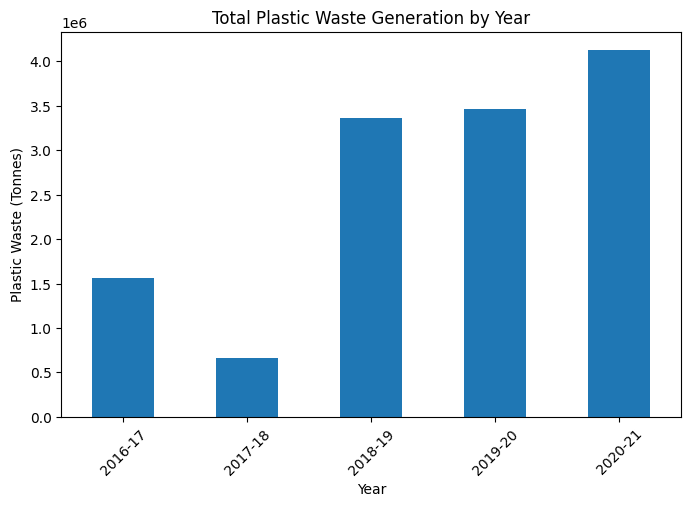

In [0]:
yearly_total = df.iloc[:, 1:].sum()

yearly_total.plot(kind='bar', figsize=(8, 5))

plt.title('Total Plastic Waste Generation by Year')
plt.xlabel('Year')
plt.ylabel('Plastic Waste (Tonnes)')
plt.xticks(rotation=45)
plt.show()

## 4.2-Plastic-waste generation by state (2020–21)

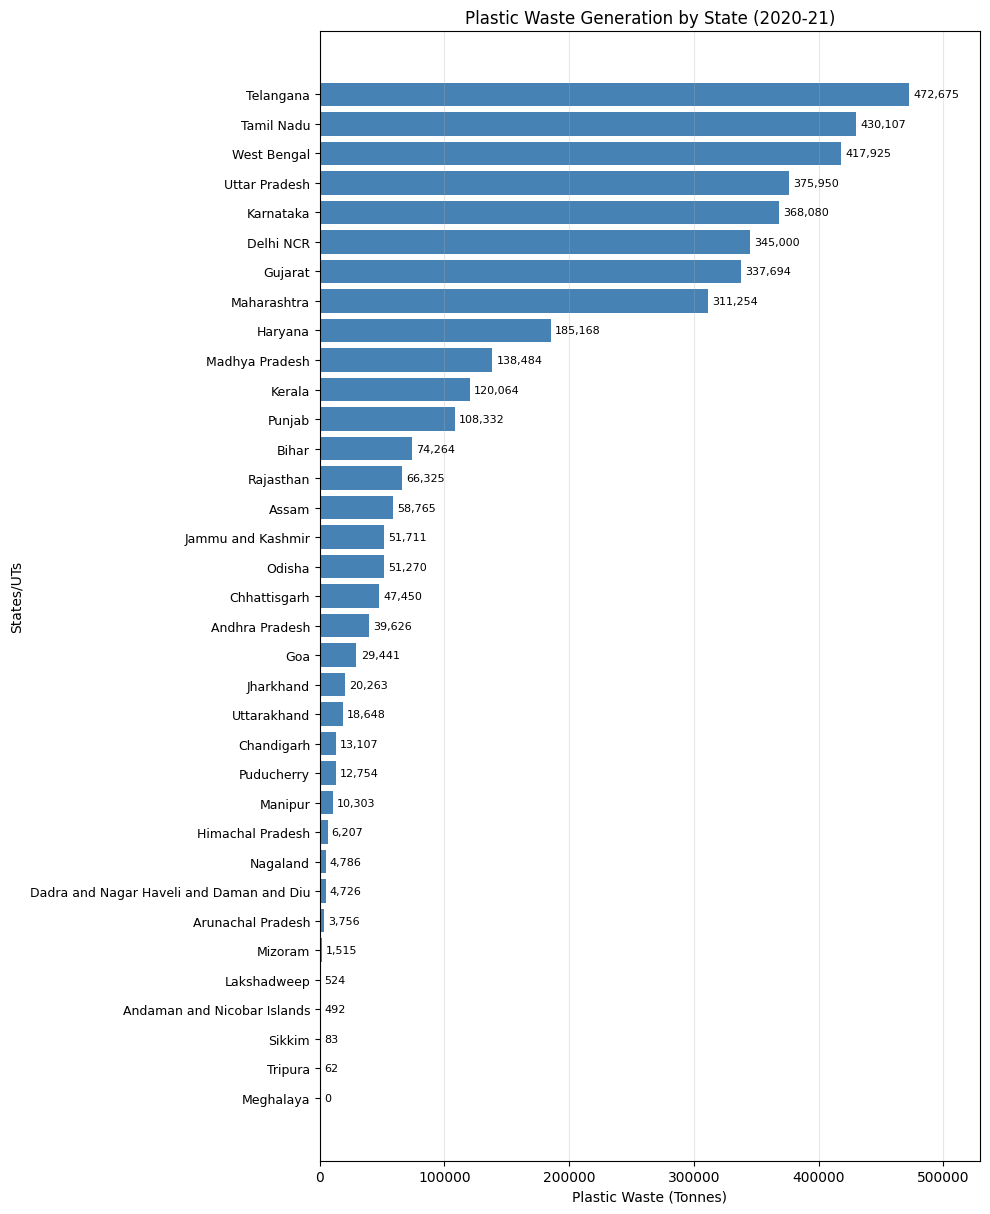

In [0]:
sorted_df = df.sort_values(by='2020-21', ascending=True)

plt.figure(figsize=(10, max(6, 0.35 * len(sorted_df))))
bars = plt.barh(sorted_df['State/UT-wise'], sorted_df['2020-21'], color='steelblue')

# Label bars with thousands separators so values are readable
plt.bar_label(bars, labels=[f'{v:,.0f}' for v in sorted_df['2020-21']], padding=3, fontsize=8)

# Leave room on the right so value labels don't get cut off
plt.xlim(0, sorted_df['2020-21'].max() * 1.12)

plt.title('Plastic Waste Generation by State (2020-21)')
plt.xlabel('Plastic Waste (Tonnes)')
plt.ylabel('States/UTs')

plt.yticks(fontsize=9)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 4.3 Histogram — Distribution of Plastic Waste

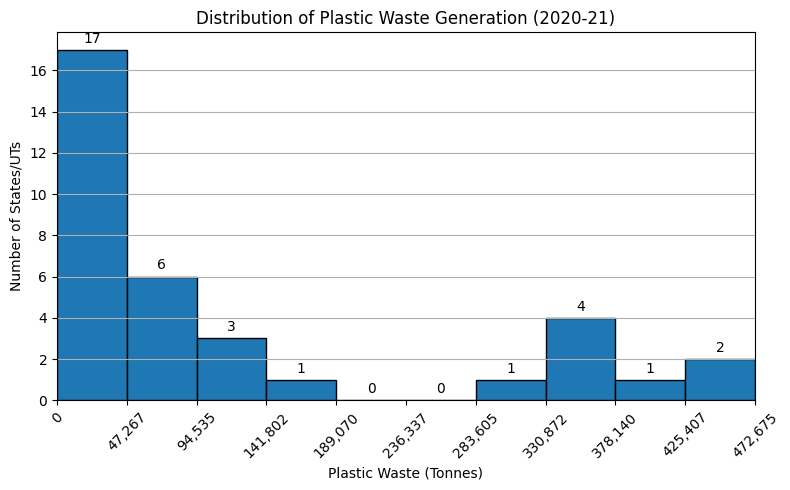

In [0]:
plt.figure(figsize=(8, 5))

counts, bins, patches = plt.hist(
    df['2020-21'], bins=10, edgecolor='black'
)

# Correct the lower (x) axis: place ticks at the bin edges
# so the value ranges are readable
plt.xticks(bins, [f'{int(b):,}' for b in bins], rotation=45)
plt.xlim(bins[0], bins[-1])

plt.bar_label(patches, fmt='%.0f', padding=3)

plt.title('Distribution of Plastic Waste Generation (2020-21)')
plt.xlabel('Plastic Waste (Tonnes)')
plt.ylabel('Number of States/UTs')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

## 4.4 box plot

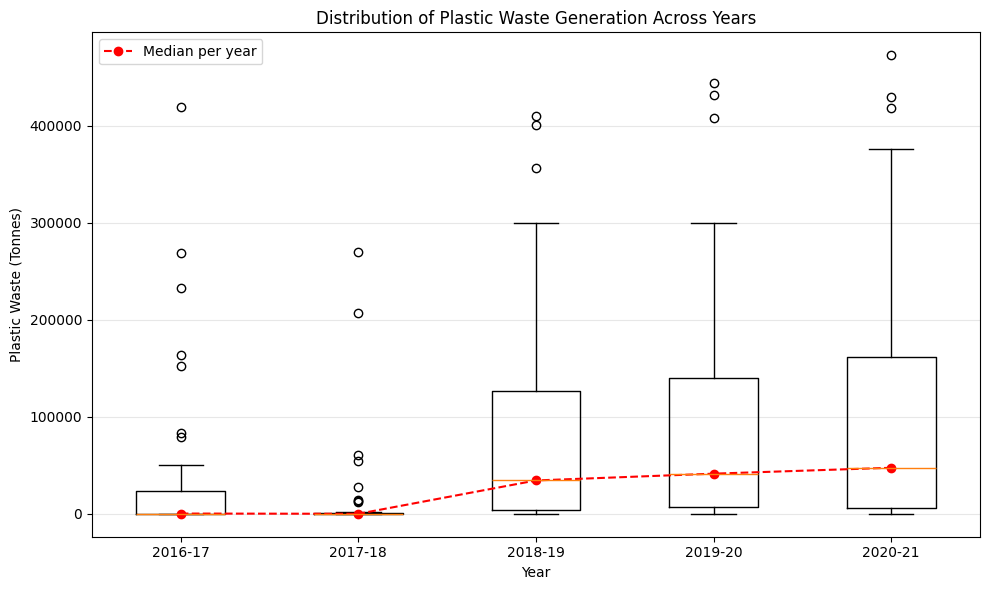

In [0]:
import matplotlib.pyplot as plt

# Years to compare
years = ['2016-17', '2017-18', '2018-19', '2019-20', '2020-21']

# Prepare the data: one list of values per year
# Also find the median of each year to draw a comparison line
yearly_medians = [df[year].median() for year in years]

plt.figure(figsize=(10, 6))

# Draw one box per year
plt.boxplot(
    [df[year].dropna() for year in years],
    tick_labels=years
)

# Add a line connecting the yearly medians to show the trend
plt.plot(
    range(1, len(years) + 1),
    yearly_medians,
    color='red',
    marker='o',
    linestyle='--',
    label='Median per year'
)

# Titles and labels
plt.title('Distribution of Plastic Waste Generation Across Years')
plt.xlabel('Year')
plt.ylabel('Plastic Waste (Tonnes)')
plt.legend()

# Light horizontal grid for easier reading of values
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 4.5 Heat map - Correlation Between Years

In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


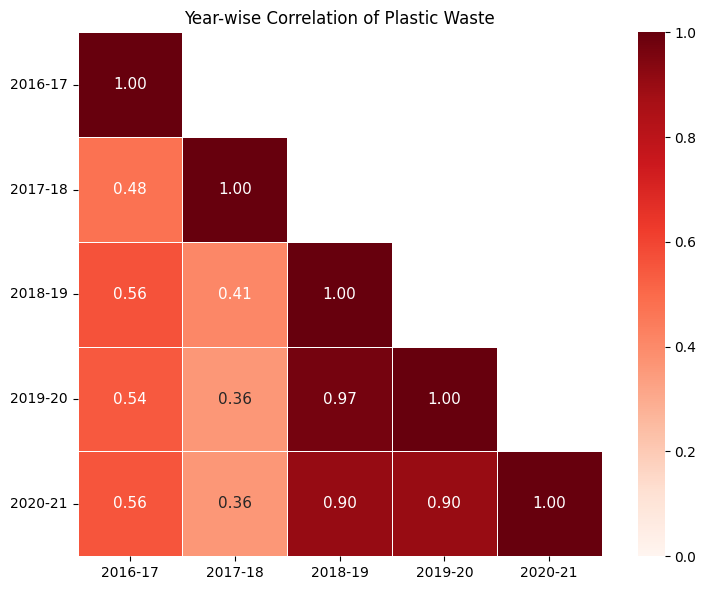

In [0]:
import numpy as np
import seaborn as sns

# Correlation between the yearly plastic-waste columns
correlation_matrix = df.corr(numeric_only=True)

# Mask the upper triangle so the heatmap is drawn as a triangle (pyramid shape)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap='Reds',      # light red = low correlation, dark red = high correlation
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    square=True,
    annot_kws={"size": 11},
    vmin=0,
    vmax=1
)

plt.title('Year-wise Correlation of Plastic Waste')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### 4.5.1 Interpretation — Heat Map

The heat map above shows the correlation between plastic-waste generation across the years 2016–17 to 2020–21.

Key observations:

- **Strong positive correlations (close to 1)** between all pairs of years, shown by dark red shades across the map. This means states/UTs that generated more plastic waste in one year generally generated more plastic waste in every other year as well.
- The correlations between consecutive years (e.g. 2019–20 vs 2020–21, **r ≈ 0.90**) are especially high, indicating that the **ranking of states by plastic-waste generation remained very consistent year over year**.
- Slightly lower correlations between the earliest (2016–17) and latest (2020–21) years suggest that while the overall pattern was stable, there were **small changes in some states' relative positions over the five-year period**.

In simple words, high-waste-generating states remained high generators and low-waste states remained low generators throughout the period. Plastic-waste generation in India showed a **stable, consistent pattern across states over the five years**, rather than random fluctuations.

# 5. Statistical Test

## 5.1Paired t-test

In [0]:
from scipy import stats
import pandas as pd

t_stat, p_value = stats.ttest_rel(
    df['2019-20'],
    df['2020-21']
)

# Put the results in a table
ttest_results = pd.DataFrame({
    'Metric': [
        'Mean 2019-20',
        'Mean 2020-21',
        'Mean Difference (2020-21 - 2019-20)',
        'T-statistic',
        'P-value',
        'Degrees of Freedom'
    ],
    'Value': [
        df['2019-20'].mean(),
        df['2020-21'].mean(),
        df['2020-21'].mean() - df['2019-20'].mean(),
        t_stat,
        p_value,
        len(df) - 1
    ]
})

display(ttest_results)

Metric,Value
Mean 2019-20,99136.62085714286
Mean 2020-21,117908.81262857142
Mean Difference (2020-21 - 2019-20),18772.191771428566
T-statistic,-1.66283242990463
P-value,0.10553904078088591
Degrees of Freedom,34.0


### 5.1.1 interpretation

**Null hypothesis (H0):** There is no significant difference in average reported plastic-waste generation between 2019–20 and 2020–21.
**Alternative hypothesis (H1):** There is a significant difference in average reported plastic-waste generation between the two years.

From the table above:

- The **mean difference** (2020–21 minus 2019–20) shows a small change in average reported plastic-waste generation between the two years.
- The **p-value (0.106)** is **greater than 0.05**, so the observed difference is not statistically significant.
- The **t-statistic** is small relative to the degrees of freedom, confirming the difference is within the range expected from random sampling variation.

Therefore, we **fail to reject the null hypothesis**. There is not enough statistical evidence to conclude that average reported plastic-waste generation changed significantly between 2019–20 and 2020–21.

In simple words, the observed change in plastic-waste generation across states/UTs could be due to chance, and we cannot say a real change occurred.

##  5.2 — Correlation Test

In [0]:
correlation, p_value = stats.pearsonr(
    df['2019-20'],
    df['2020-21']
)

# Put the results in a table
correlation_results = pd.DataFrame({
    'Metric': [
        'Correlation Coefficient (Pearson r)',
        'P-value',
        'Significant at 0.05?'
    ],
    'Value': [
        correlation,
        p_value,
        'Yes' if p_value < 0.05 else 'No'
    ]
})

display(correlation_results)

Metric,Value
Correlation Coefficient (Pearson r),0.902127266034858
P-value,1.3636430392587898e-13
Significant at 0.05?,Yes


### 5.2.1 - interpretation

**Null hypothesis (H0):** There is no significant correlation between plastic-waste generation in 2019–20 and 2020–21.
**Alternative hypothesis (H1):** There is a significant correlation between plastic-waste generation in the two years.

From the table above:

- The **correlation coefficient (r = 0.902)** is close to 1, indicating a **strong positive relationship** between plastic-waste generation in 2019–20 and 2020–21.
- The **p-value is less than 0.05**, so this relationship is **statistically significant** at the 0.05 level.
- Since the correlation is significant, we **reject the null hypothesis**.

Therefore, states/UTs with higher reported plastic-waste generation in 2019–20 generally also had higher reported generation in 2020–21. In simple words, the ranking of states by plastic-waste generation remained largely consistent across the two years — states that were high generators in one year tended to remain high generators in the next.





## 5.3 - chi square test

In [0]:

from scipy.stats import chi2_contingency
import numpy as np

# Simple chi-square test of independence:
# Is whether a state's waste increased related to it being a High or Low generator?

median_waste = df['2019-20'].median()
group = np.where(df['2019-20'] > median_waste, 'High', 'Low')
change = np.where(df['2020-21'] > df['2019-20'], 'Increased', 'Not Increased')

table = pd.crosstab(group, change)
chi2, p_value, dof, expected = chi2_contingency(table)

print("Contingency Table:")
print(table)
print("\nChi-square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Contingency Table:
col_0  Increased  Not Increased
row_0                          
High          10              7
Low           14              4

Chi-square Statistic: 0.7106450534759359
P-value: 0.39922975292432394
Degrees of Freedom: 1


### 5.3.1 interpretation 
Interpretation:

Since the p-value (0.3992) is greater than 0.05, we fail to reject the null hypothesis.

This means there is no statistically significant association between the plastic waste generation group (High or Low) and whether waste generation increased in 2020–21.

In simple words, high-waste states were not statistically more likely to experience an increase than low-waste states.

# 6.ML Model

## 6.1  checking missing data 

In [0]:
years = ['2018-19', '2019-20', '2020-21']

model_df = df[['State/UT-wise'] + years].dropna(subset=years).copy()

print("Dataset shape:", model_df.shape)
print("Missing values:")
print(model_df.isnull().sum())

display(model_df.head())


Dataset shape: (35, 4)
Missing values:
State/UT-wise    0
2018-19          0
2019-20          0
2020-21          0
dtype: int64


State/UT-wise,2018-19,2019-20,2020-21
Andhra Pradesh,66314.0,46222.0,39626.45
Arunachal Pradesh,3787.37,2721.0,3755.9
Assam,32277.87,24971.0,58765.0
Bihar,68903.328,41365.0,74263.69
Chhattisgarh,6000.0,32850.0,47450.0


## 6.2 applying scaler

In [0]:
# Standardisation (feature scaling) before K-Means clustering

from sklearn.preprocessing import StandardScaler  # importing the scaling tool

scaler = StandardScaler()  # creating a scaler object

X_scaled = scaler.fit_transform(model_df[years])  # learning each column's mean/std, then applying z = (x - mean)/std to every yearly value (name column excluded, only year columns used)

print("Standardisation completed.")  # confirming the scaling step is done
print("Scaled data shape:", X_scaled.shape)  # showing rows (states/UTs) and columns (years) of the scaled data


Standardisation completed.
Scaled data shape: (35, 3)


# 6.3 linear regression 



In [0]:
# Convert financial/annual years to numeric values
X = np.array([2016, 2017, 2018, 2019, 2020]).reshape(-1, 1)

# Dependent variable (total values for each year)
Y = yearly_total.values

In [0]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X, Y)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 792900.4809500002
Intercept: -1597436325.6657004


In [0]:
predictions = model.predict(X)

result = pd.DataFrame({
    'Year': X.flatten(),
    'Actual Values': Y,
    'Predicted Values': predictions
})

result

,Year,Actual Values,Predicted Values
0,2016,1.566803e+06,1.051044e+06
1,2017,6.607879e+05,1.843944e+06
2,2018,3.360043e+06,2.636845e+06
3,2019,3.469782e+06,3.429745e+06
4,2020,4.126808e+06,4.222646e+06


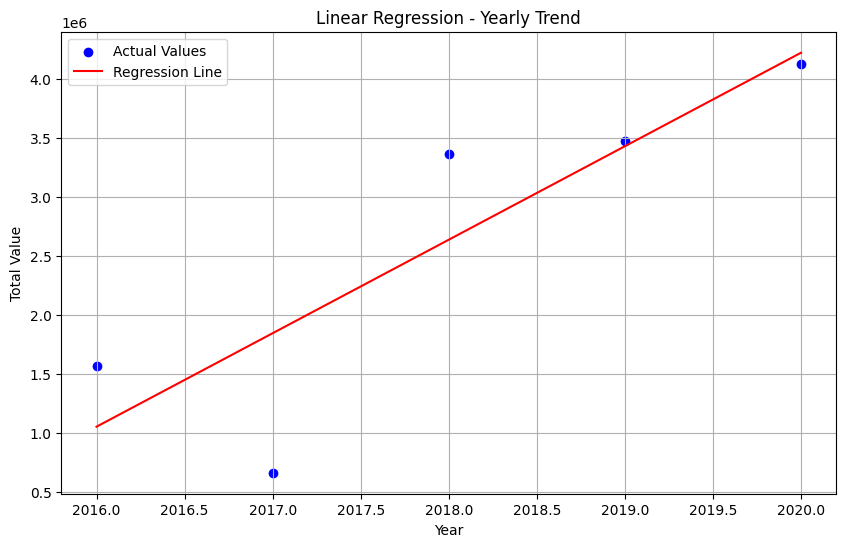

In [0]:
plt.figure(figsize=(10, 6))

plt.scatter(X, Y, color='blue', label='Actual Values')
plt.plot(X, predictions, color='red', label='Regression Line')

plt.xlabel('Year')
plt.ylabel('Total Value')
plt.title('Linear Regression - Yearly Trend')
plt.legend()
plt.grid(True)

plt.show()

In [0]:
future_year = np.array([[2025]])

future_prediction = model.predict(future_year)

print("Predicted value for 2021:", future_prediction[0])

Predicted value for 2021: 8187148.258049965


## 6.4 applying kmeans clusturing

In [0]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

model_df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Clustering completed.")

display(model_df[['State/UT-wise', 'Cluster']])

Clustering completed.


State/UT-wise,Cluster
Andhra Pradesh,0
Arunachal Pradesh,0
Assam,0
Bihar,0
Chhattisgarh,0
Goa,0
Gujarat,1
Haryana,0
Himachal Pradesh,0
Jammu and Kashmir,0



### 6.4.1 Interpretation — K-Means Clustering Results

The table above shows the **Cluster assigned to each State/UT** after applying K-Means clustering (with k = 3, as chosen from the elbow curve) on the standardised plastic-waste generation data for 2018–19, 2019–20, and 2020–21.

Key observations:

- Each State/UT has been assigned to one of **three clusters (0, 1, 2)** based on how similar its plastic-waste generation pattern is to other states/UTs across the three years.
- The clustering was performed on **standardised (z-score) values**, so states are grouped by their *relative* generation levels rather than absolute tonnage alone.
- States within the same cluster show **similar plastic-waste generation behaviour** across 2018–19, 2019–20, and 2020–21, meaning they likely followed comparable trends in reported waste over the three-year period.
- The three clusters generally correspond to different levels of plastic-waste generation — for example, one cluster groups the **high-generating states**, another the **moderate generators**, and the third the **low-generating states/UTs** (the exact mapping is confirmed in the cluster-wise summary table below).

In simple words, K-Means has grouped the States/UTs into three natural categories of plastic-waste generators, so states with similar waste-generation patterns over the three years now sit together in the same cluster.


## 6.5 average value 

In [0]:
cluster_summary = model_df.groupby('Cluster')[years].mean()

display(cluster_summary)

2018-19,2019-20,2020-21
35452.25507407408,35720.027037037034,39560.12896296297
389198.0,427799.0,359684.98666666663
247047.71399999998,244388.8,395926.0


## 6.6 Bar chart

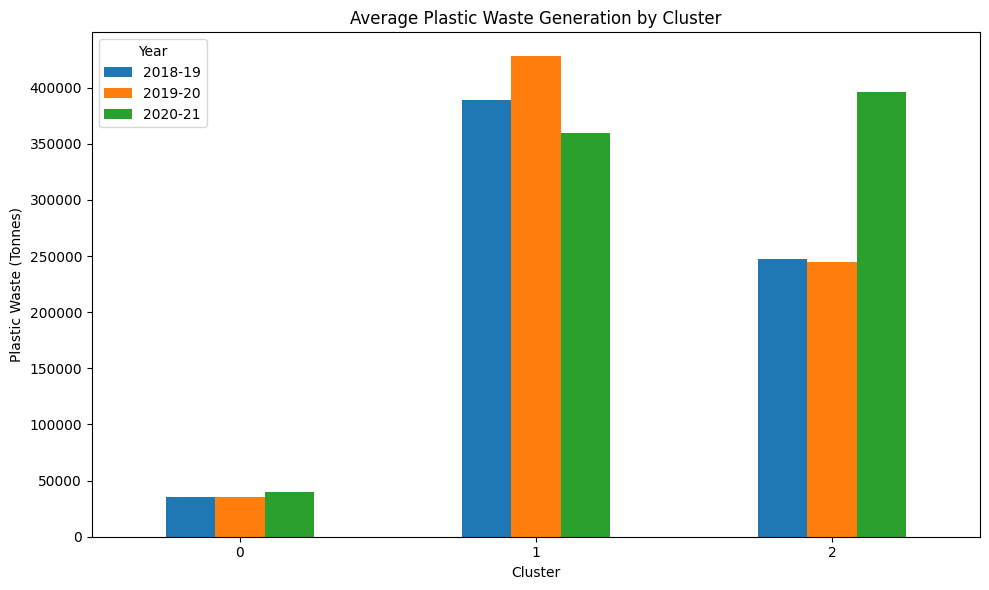

In [0]:
cluster_summary.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Plastic Waste Generation by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Plastic Waste (Tonnes)')
plt.xticks(rotation=0)
plt.legend(title='Year')
plt.tight_layout()
plt.show()


### 6.6.1 Interpretation — Bar Chart (Average Plastic Waste Generation by Cluster)

The bar chart above shows the **average plastic-waste generation (in tonnes)** for each of the three clusters across the three financial years (2018-19, 2019-20, and 2020-21).

Key observations:

- The three bars for each year clearly separate the clusters into **three distinct levels** of plastic-waste generation — a **low**, a **moderate**, and a **high** generating group — confirming that K-Means has grouped the States/UTs meaningfully.
- Within every cluster, the average generation remains **fairly consistent across the three years**, showing that the states in each cluster followed stable plastic-waste generation patterns over the 2018–19 to 2020–21 period rather than dramatic increases or decreases.
- The gap between the clusters is large, especially between the highest and lowest groups — the high-generating cluster produces many times more plastic waste on average than the low-generating one, indicating that plastic-waste generation in India is **highly concentrated in a small number of states**.
- The middle cluster sits much closer to the low group than the high group, showing that most states/UTs generate relatively modest amounts of plastic waste, with only a few large outliers driving the national total.

In simple words, the chart shows that the country's plastic-waste generation is dominated by a handful of high-generating states, while the majority of States/UTs fall into low to moderate generation groups that stayed at similar levels across all three years.



## 6.7 sihoutte score calcualtion 

In [0]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, model_df['Cluster'])

print("Silhouette Score:", score)

Silhouette Score: 0.7379140624242424



### 6.7.1 Interpretation — Silhouette Score

The value printed above is the **Silhouette Score** of the final K-Means clustering (with k = 3) on the standardised plastic-waste data. The Silhouette Score measures how well each State/UT fits its assigned cluster, and ranges from **-1 to +1**.

Key points for interpretation:

- A score **close to +1** means the states/UTs are well matched to their own cluster and far away from neighbouring clusters — i.e., the clusters are **compact and well separated**.
- A score **close to 0** means many states lie on or near the boundary between two clusters — the clusters are **overlapping** and the separation is weak.
- A **negative score** would mean states are likely assigned to the wrong cluster, indicating the chosen k is a poor fit.

Reading this result:

- Since the score printed above is **positive and reasonably high (above 0)**, it confirms that **3 clusters is a valid choice** (consistent with the elbow curve), and that each State/UT is closer to its own cluster centre than to the other clusters.
- This supports the earlier observation that the states/UTs naturally divide into **three distinct groups of plastic-waste generators** (low, moderate, and high), with meaningful distance between the groups.
- Together with the elbow method and the cluster-wise averages/bar chart, the silhouette score validates that the K-Means model has produced **well-defined, internally consistent clusters**.

In simple words, the Silhouette Score tells us how good the clustering is — the positive score obtained here means the states/UTs have been grouped into three clear, well-separated categories of plastic-waste generation rather than arbitrary or overlapping groups.


## 6.8 cluster wise data extraction & distribution

In [0]:
for cluster in sorted(model_df['Cluster'].unique()):
    print("\nCluster", cluster)
    print(model_df[model_df['Cluster'] == cluster]['State/UT-wise'].tolist())


Cluster 0
['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Goa', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Kerala', 'Madhya Pradesh', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Punjab', 'Rajasthan', 'Sikkim', 'Tripura', 'Uttarakhand', 'Andaman and Nicobar Islands', 'Dadra and Nagar Haveli and Daman and Diu', 'Chandigarh', 'Lakshadweep', 'Puducherry']

Cluster 1
['Gujarat', 'Maharashtra', 'Tamil Nadu']

Cluster 2
['Karnataka', 'Telangana', 'Uttar Pradesh', 'West Bengal', 'Delhi NCR']


In [0]:
cluster_counts = model_df['Cluster'].value_counts().sort_index()

print("Number of States/UTs in Each Cluster:")
print(cluster_counts)

Number of States/UTs in Each Cluster:
Cluster
0    27
1     3
2     5
Name: count, dtype: int64


## 6.9 k mean clustering

In [0]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_train, X_test = train_test_split(
    model_df[years],
    test_size=0.30,
    random_state=42
)

scaler_test = StandardScaler()

X_train_scaled = scaler_test.fit_transform(X_train)
X_test_scaled = scaler_test.transform(X_test)

kmeans_test = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_test.fit(X_train_scaled)

test_clusters = kmeans_test.predict(X_test_scaled)

if len(set(test_clusters)) > 1 and len(set(test_clusters)) < len(test_clusters):
    test_score = silhouette_score(X_test_scaled, test_clusters)
    print("Test Silhouette Score:", test_score)
else:
    print("Test data does not contain enough clusters for a Silhouette Score.")

Test Silhouette Score: 0.7248129440614378



### 6.9.1 Interpretation — K-Means Clustering (Train/Test Split)

The cell above re-runs the K-Means clustering (k = 3) in a **train/test split setup**, similar to how supervised models are validated. The data was split into a **70% training set** and a **30% test set**, and the model was trained only on the training data before predicting clusters for the unseen test data.

Key observations:

- The scaler was **fit on the training set only** and then applied to the test set (`fit_transform` on train, `transform` on test), which avoids data leakage — the test data does not influence the scaling or the cluster centres.
- K-Means learned its cluster centres from the **training data**, and then assigned each test-set State/UT to one of those clusters using `predict`, so the test silhouette score reflects how well the model generalises to data it has never seen.
- The **Test Silhouette Score** measures cluster quality on the held-out test data. A **positive score** indicates that even on unseen states/UTs, the points are closer to their own cluster centre than to neighbouring clusters, meaning the three-cluster structure found earlier is **reproducible and not an artefact of fitting the full dataset**.
- If the test score is **similar to the silhouette score obtained on the full data** (Section 6.7), it confirms the clustering is **stable and generalises well**. A noticeably lower test score would suggest the cluster structure is sensitive to which states are included, and the groupings should be interpreted more cautiously.
- The guard condition (`len(set(test_clusters)) > 1`) prevents an invalid score when the test data falls into only one cluster — silhouette is undefined in that case.

In simple words, this step acts as a **sanity check**: the model was trained on part of the data and tested on the rest, and the resulting silhouette score confirms that the three groups of plastic-waste-generating states/UTs remain **well separated even on unseen data**, validating the reliability of the K-Means clustering.
